# <span style="color: #a855f7">CNN image classification</span>

<span style="color: #a855f7">класифікація рукописних цифр 0–9 на MNIST, базова CNN у PyTorch, 10 епох навчання, графік loss і перевірка Accuracy та CrossEntropyLoss на test, початкове завантаження потребує інтернету, наступні запуски використовують локальні дані</span>

In [1]:
import os
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import HTML, display
from matplotlib.ticker import MaxNLocator
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

RANDOM_STATE = 42
BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 0.001
CPU_THREADS = min(4, os.cpu_count() or 1)
DATA_ROOT = Path("data")
MODEL_PATH = Path("mnist_cnn.pth")
LOSS_PLOT_PATH = Path("mnist_cnn_loss.png")
COLORS = ["#a855f7", "#f472b6", "#60a5fa"]

torch.manual_seed(RANDOM_STATE)
torch.set_num_threads(CPU_THREADS)


def colorize(value, *, index=True):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        table = value.to_frame() if isinstance(value, pd.Series) else value
        html = table.to_html(border=0, index=index).replace(
            '<table ', '<table style="color: #a855f7; margin-left: 0; margin-right: auto; border-collapse: collapse" '
        )
        for tag in ("th", "td"):
            html = html.replace(
                f"<{tag}>",
                f'<{tag} style="padding: 6px 12px; border-bottom: 1px solid #746a80">',
            )
        display(HTML(html))
    else:
        display(HTML(f'<p style="color: #a855f7; margin: 12px 0 6px">{escape(str(value))}</p>'))


plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "#111116",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#746a80",
    "axes.labelcolor": "#e9d5ff",
    "axes.titlecolor": "#e9d5ff",
    "axes.titlesize": 13,
    "text.color": "#e9d5ff",
    "xtick.color": "#d8c8ed",
    "ytick.color": "#d8c8ed",
    "grid.color": "#746a80",
    "grid.alpha": 0.25,
    "font.size": 10,
})

## <span style="color: #a855f7">MNIST data and loaders</span>

<span style="color: #a855f7">MNIST містить 60000 train і 10000 test зображень розміром 28×28 з одним каналом, ToTensor переводить пікселі у float32 в межах [0, 1], Normalize з mean=0.5 і std=0.5 дає шкалу [-1, 1], однакове перетворення застосовується до обох вибірок, batch_size=64, перемішується лише train, дані зберігаються в data поруч із Notebook і виключені з Git</span>

In [2]:
class FlatMNIST(datasets.MNIST):
    @property
    def raw_folder(self) -> str:
        return os.fspath(self.root)


transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
train_dataset = FlatMNIST(DATA_ROOT, train=True, download=True, transform=transform)
test_dataset = FlatMNIST(DATA_ROOT, train=False, download=True, transform=transform)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(RANDOM_STATE),
)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
sample_image, sample_label = train_dataset[0]
if sample_image.shape != (1, 28, 28) or not torch.isfinite(sample_image).all():
    raise ValueError("MNIST images must have shape (1, 28, 28) and finite pixel values")
colorize(pd.DataFrame({
    "split": ["train", "test"],
    "images": [len(train_dataset), len(test_dataset)],
    "batch size": [train_loader.batch_size, test_loader.batch_size],
    "batches": [len(train_loader), len(test_loader)],
    "image shape": [str(tuple(sample_image.shape))] * 2,
}), index=False)
colorize(pd.DataFrame({
    "digit": list(range(10)),
    "train images": torch.bincount(train_dataset.targets, minlength=10).tolist(),
    "test images": torch.bincount(test_dataset.targets, minlength=10).tolist(),
}), index=False)
colorize(pd.DataFrame([{
    "sample label": sample_label,
    "dtype": str(sample_image.dtype),
    "minimum pixel": sample_image.min().item(),
    "maximum pixel": sample_image.max().item(),
}]), index=False)

split,images,batch size,batches,image shape
train,60000,64,938,"(1, 28, 28)"
test,10000,64,157,"(1, 28, 28)"


digit,train images,test images
0,5923,980
1,6742,1135
2,5958,1032
3,6131,1010
4,5842,982
5,5421,892
6,5918,958
7,6265,1028
8,5851,974
9,5949,1009


sample label,dtype,minimum pixel,maximum pixel
5,torch.float32,-1.0,1.0


## <span style="color: #a855f7">CNN architecture</span>

<span style="color: #a855f7">точна послідовність Conv2d(1, 16, kernel_size=3) → ReLU → MaxPool2d(2) → Flatten → Linear(16 × 13 × 13, 10), без padding згортка змінює 28×28 на 26×26, pooling дає 13×13, вихід - 10 logits, Softmax перед CrossEntropyLoss не додається, обчислення виконуються на CPU</span>

In [3]:
def create_model():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(16 * 13 * 13, 10),
    )


torch.manual_seed(RANDOM_STATE)
model = create_model()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
layer_rows = []
with torch.no_grad():
    probe = torch.zeros(1, 1, 28, 28)
    for layer in model:
        input_shape = tuple(probe.shape)
        probe = layer(probe)
        layer_rows.append({
            "layer": type(layer).__name__,
            "input shape": str(input_shape),
            "output shape": str(tuple(probe.shape)),
            "parameters": sum(parameter.numel() for parameter in layer.parameters()),
        })
colorize(pd.DataFrame(layer_rows), index=False)
colorize(f"Trainable parameters: {sum(parameter.numel() for parameter in model.parameters())}")

layer,input shape,output shape,parameters
Conv2d,"(1, 1, 28, 28)","(1, 16, 26, 26)",160
ReLU,"(1, 16, 26, 26)","(1, 16, 26, 26)",0
MaxPool2d,"(1, 16, 26, 26)","(1, 16, 13, 13)",0
Flatten,"(1, 16, 13, 13)","(1, 2704)",0
Linear,"(1, 2704)","(1, 10)",27050


## <span style="color: #a855f7">Training for 10 epochs</span>

<span style="color: #a855f7">Adam з lr=0.001 і CrossEntropyLoss, кожна епоха проходить всі 60000 train-зображень, градієнти очищуються перед кожним батчем, loss епохи - середнє значення втрат за навчальними батчами з врахуванням їхнього розміру, останній неповний батч не відкидається, test не використовується для навчання чи вибору епохи</span>

In [4]:
history = []
status = display(HTML('<p style="color: #a855f7">Training started</p>'), display_id=True)
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    samples_seen = 0
    for images, labels in train_loader:
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("Training loss is not finite")
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        samples_seen += images.size(0)
    epoch_loss = total_loss / samples_seen
    history.append({"epoch": epoch, "train loss": epoch_loss})
    if status is not None:
        status.update(HTML(f'<p style="color: #a855f7">Epoch {epoch}/{EPOCHS} | train loss: {epoch_loss:.6f} | images: {samples_seen}</p>'))
training_results = pd.DataFrame(history)
colorize(training_results.round(6), index=False)

epoch,train loss
1,0.261017
2,0.092228
3,0.068585
4,0.058045
5,0.049681
6,0.044086
7,0.039891
8,0.035498
9,0.030868
10,0.029163


## <span style="color: #a855f7">Loss curve</span>

<span style="color: #a855f7">вісь X - епохи 1–10, вісь Y - середній train CrossEntropyLoss, крива показує процес оптимізації на train, не є оцінкою якості на нових даних, графік додатково збережений як mnist_cnn_loss.png</span>

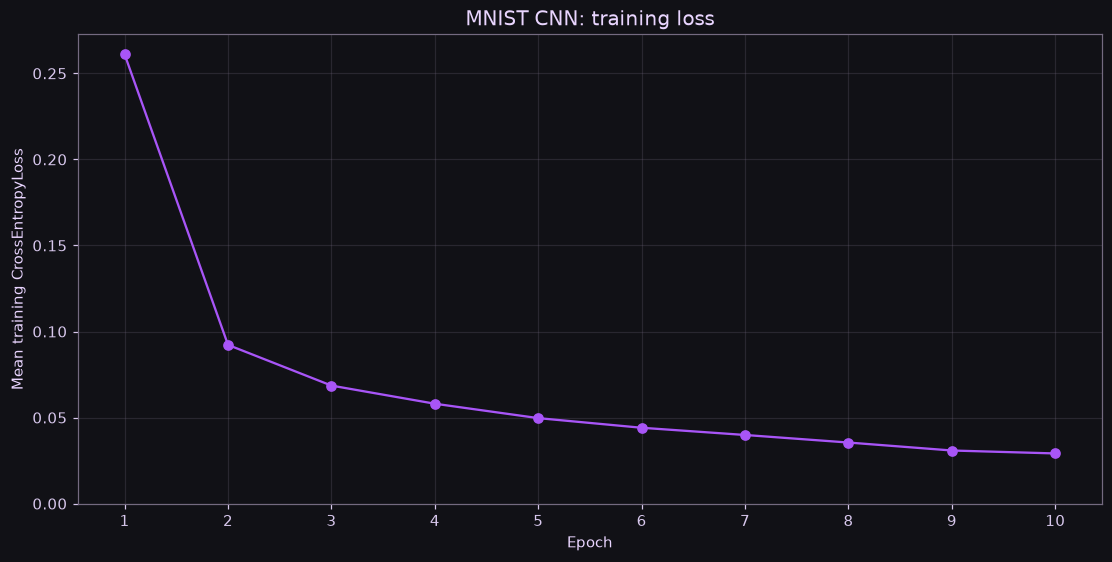

In [5]:
fig, ax = plt.subplots(layout="constrained")
ax.plot(training_results["epoch"].to_numpy(), training_results["train loss"].to_numpy(), color=COLORS[0], marker="o")
ax.set(title="MNIST CNN: training loss", xlabel="Epoch", ylabel="Mean training CrossEntropyLoss")
ax.set_xticks(training_results["epoch"].tolist())
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylim(bottom=0)
ax.grid(True)
ax.set_axisbelow(True)
fig.savefig(LOSS_PLOT_PATH, dpi=160, facecolor=fig.get_facecolor())
plt.show()

## <span style="color: #a855f7">Saving and loading model weights</span>

<span style="color: #a855f7">torch.save зберігає state_dict у mnist_cnn.pth, файл містить навчені ваги, архітектуру відтворює create_model, перед тестуванням ваги завантажуються у нову модель через weights_only=True, це перевіряє придатність збереженого файлу для повторного використання</span>

In [6]:
torch.save(model.state_dict(), MODEL_PATH)
restored_model = create_model()
restored_model.load_state_dict(torch.load(MODEL_PATH, map_location="cpu", weights_only=True))
restored_model.eval()
colorize(pd.DataFrame([{
    "file": MODEL_PATH.name,
    "size (bytes)": MODEL_PATH.stat().st_size,
    "contents": "state_dict",
    "loaded": True,
}]), index=False)

file,size (bytes),contents,loaded
mnist_cnn.pth,111345,state_dict,True


## <span style="color: #a855f7">Test accuracy and loss</span>

<span style="color: #a855f7">model.eval і torch.inference_mode вимикають обчислення градієнтів під час оцінювання, всі 10000 test-зображень проходять збережену й повторно завантажену модель, Accuracy - частка правильних класів, Loss - середній CrossEntropyLoss на всьому test з врахуванням розміру кожного батча, test не використовувався для оновлення ваг</span>

In [7]:
total_test_loss = 0.0
correct = 0
test_samples = 0
with torch.inference_mode():
    for images, labels in test_loader:
        logits = restored_model(images)
        batch_loss = criterion(logits, labels)
        total_test_loss += batch_loss.item() * images.size(0)
        correct += int((logits.argmax(dim=1) == labels).sum().item())
        test_samples += images.size(0)
accuracy = correct / test_samples
test_loss = total_test_loss / test_samples
test_results = pd.DataFrame({
    "metric": ["Accuracy", "Loss"],
    "value": [accuracy, test_loss],
})
colorize(test_results.round(6), index=False)
colorize(f"Correct predictions: {correct}/{test_samples} | accuracy: {accuracy:.2%}")

metric,value
Accuracy,0.979600
Loss,0.067547


## <span style="color: #a855f7">Prediction examples</span>

<span style="color: #a855f7">перші 12 test-зображень без відбору за правильністю прогнозу, True - правильна цифра з датасету, Predicted - клас, обраний збереженою моделлю, фіолетовий підпис означає збіг, рожевий - помилку, приклади доповнюють метрики на всіх 10000 зображень</span>

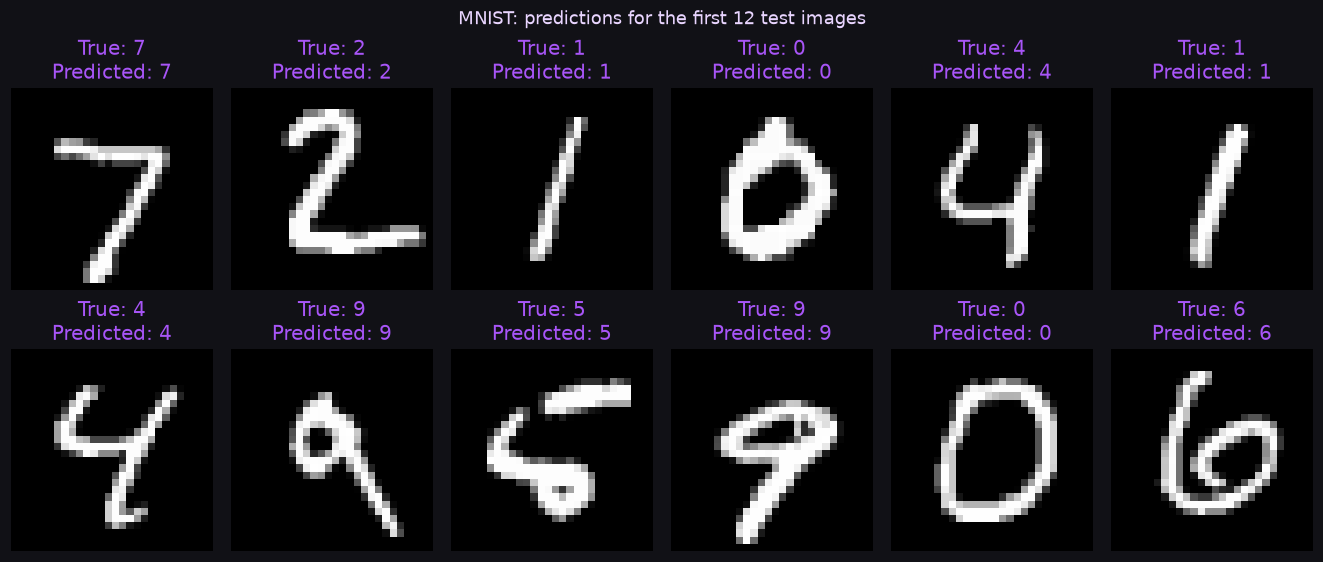

In [8]:
preview_count = 12
preview_images = torch.stack([test_dataset[index][0] for index in range(preview_count)])
preview_labels = test_dataset.targets[:preview_count]
with torch.inference_mode():
    preview_predictions = restored_model(preview_images).argmax(dim=1)
fig_preview, axes_preview = plt.subplots(2, preview_count // 2, figsize=(12, 5), layout="constrained")
for image_ax, image, actual, predicted in zip(
    axes_preview.flat, preview_images, preview_labels.tolist(), preview_predictions.tolist(), strict=True,
):
    image_ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=-1, vmax=1, interpolation="nearest")
    image_ax.set_title(f"True: {actual}\nPredicted: {predicted}", color=COLORS[0] if actual == predicted else COLORS[1])
    image_ax.axis("off")
fig_preview.suptitle("MNIST: predictions for the first 12 test images")
fig_preview.savefig("mnist_cnn_predictions.png", dpi=160, facecolor=fig_preview.get_facecolor())
plt.show()

<span style="color: #a855f7">таблиця містить тестові метрики збереженої моделі, зменшення train loss показує навчання, але узагальнення оцінюється окремо на test, модель класифікує окремі цифри MNIST</span>